# Bagging: baseline and tuned classifier
**Review 2 · Classification Part B · target: transmission**

Predict Automatic vs Manual using 2,500 distinct real UK listing records (1,250 per class).
Prices are GBP and distance is miles. Source records come from Aditya Desai's UK used-car dataset;
no synthetic or repeated training rows are added. Distinct rows do not establish VIN-level uniqueness.

The fixed 80:20 stratified split gives 2,000 training rows and 500 test rows, with equal classes in both.
**No oversampling or class weights are needed.** Fit imputation, scaling and encoding inside each fold.
All Part A and B reruns share this new dataset and split; these are not the original Review 1 scores.
The balanced test sample measures performance for this sampled population, not natural market prevalence.

Selection uses **five-fold macro F1**, which gives both classes equal importance. Required weighted
metrics are also reported. The test set is used for the final before/after comparison, never to choose parameters.
The same feature engineering, preprocessing are used before and after tuning.


In [1]:
from pathlib import Path
import sys, os, warnings, json
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the extracted project/notebooks folder.')
sys.path.insert(0, str(ROOT))
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
from sklearn.base import clone
from sklearn.model_selection import cross_validate, GridSearchCV
from src.classification import *
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]
display(pd.DataFrame({'Raw': raw[TARGET].value_counts(), 'Cleaned': df[TARGET].value_counts(),
                      'Train': y_train.value_counts(), 'Test': y_test.value_counts()}))
display(df.dtypes.to_frame('dtype').astype(str))
print('Removed exact duplicate rows:', len(raw) - len(df))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Removed exact duplicate rows: 0


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## Training-data audit and EDA
Missing numeric/categorical values, if present, are imputed within each training fold.
Car age uses a fixed reference year (2026); log price/log miles reduce positive skew. Brand, model,
fuel, tax, MPG and engine displacement remain available to the classifier. IQR outliers
are reported and retained rather than deleting legitimate expensive or high-mileage cars.

**Team task:** write your own observations from each plot and justify these feature choices, as required by the guidelines.


Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


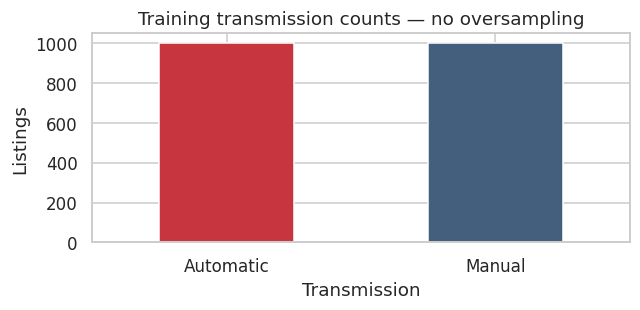

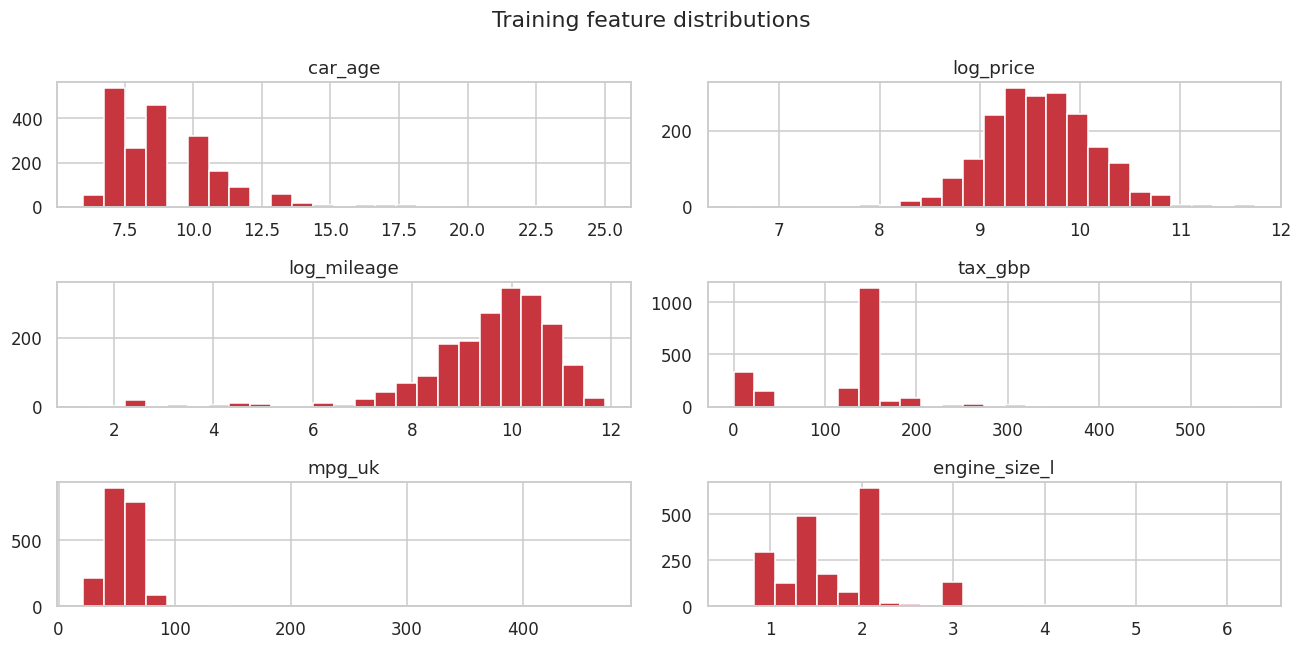

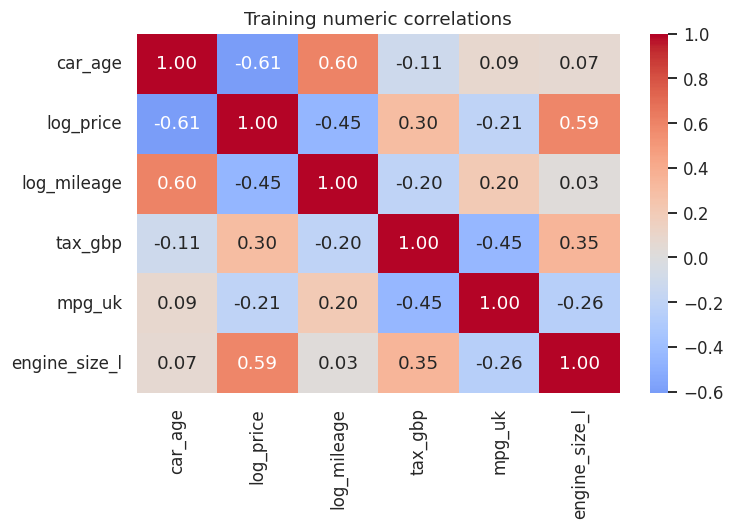

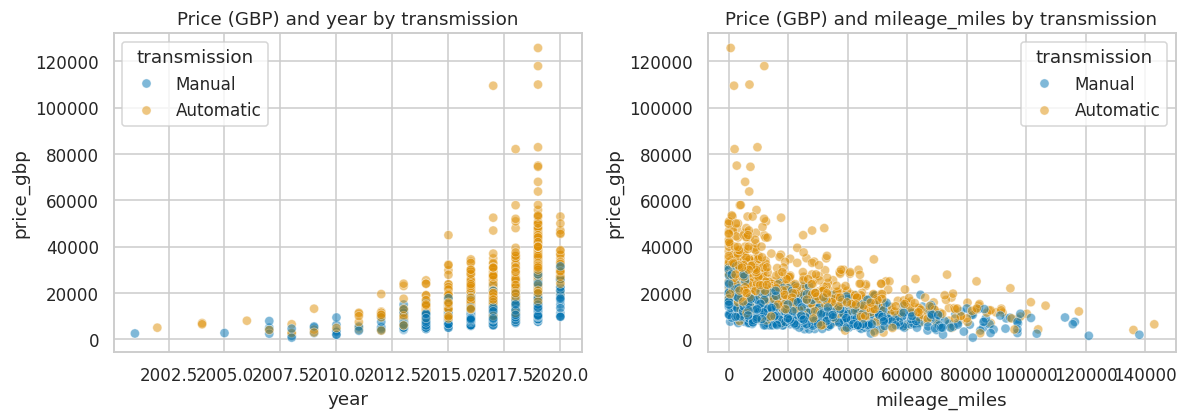

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


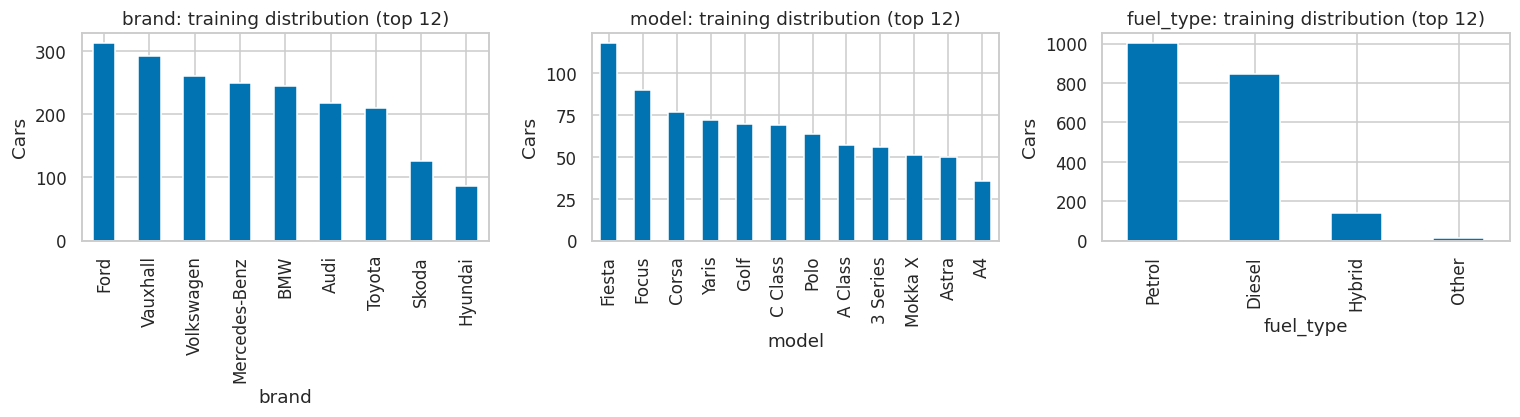

In [2]:
audit_plots(df, train)
display(train.describe(include='all').T)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
features = CarFeatures().transform(X_train)
for ax, col in zip(axes.ravel(), ['brand', 'model', 'fuel_type']):
    features[col].value_counts().head(12).plot.bar(ax=ax)
    ax.set(title=f'{col}: training distribution (top 12)', xlabel=col, ylabel='Cars')
plt.tight_layout(); plt.show()


## Model and search space
The displayed estimator is the untuned baseline. The search includes its parameter settings. A tied or lower test score after tuning is reported honestly.

In [3]:
slug = 'bagging'
name, estimator, parameter_grid = configurations()[slug]
display(estimator)
display(parameter_grid)
baseline = build_pipeline(clone(estimator))
warning_messages = []


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",10
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary `... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


[{'model__n_estimators': [10],
  'model__max_samples': [1.0],
  'model__estimator__max_depth': [None]},
 {'model__n_estimators': [50, 100],
  'model__max_samples': [0.8],
  'model__estimator__max_depth': [8, None]}]

## Before tuning: five-fold CV and full training fit

In [4]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    baseline_cv = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING,
                                 n_jobs=1, error_score='raise')
    baseline.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
display(pd.DataFrame({k: v for k, v in baseline_cv.items() if k.startswith('test_')}))
print('Mean baseline macro F1:', baseline_cv['test_f1_macro'].mean())


Mean baseline macro F1: 0.8354257047227776


,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.867479,0.867479,0.8675
1,0.837418,0.837418,0.8375
2,0.814981,0.814981,0.8150
3,0.835000,0.835000,0.8350
4,0.822250,0.822250,0.8225


## After tuning: GridSearchCV
Imputation, encoding and scaling are refitted independently inside each fold. The MLP uses a fixed convergence budget without internal early stopping; no test rows are used while fitting.

In [5]:
search = GridSearchCV(build_pipeline(clone(estimator)), parameter_grid,
                      scoring=SCORING, refit='f1_macro', cv=CV,
                      n_jobs=1, error_score='raise', return_train_score=False)
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    search.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
tuned = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best training CV macro F1:', search.best_score_)
display(pd.DataFrame(search.cv_results_)[['params', 'mean_test_f1_macro',
    'std_test_f1_macro', 'mean_test_f1_weighted', 'rank_test_f1_macro']].sort_values('rank_test_f1_macro'))
print('Recorded training warnings:', sorted(set(warning_messages)) or 'None')


Best parameters: {'model__estimator__max_depth': None, 'model__max_samples': 0.8, 'model__n_estimators': 100}
Best training CV macro F1: 0.8489223706213039
Recorded training warnings: None


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_f1_weighted,rank_test_f1_macro
4,"{'model__estimator__max_depth': None, 'model__...",0.848922,0.025832,0.848922,1
3,"{'model__estimator__max_depth': None, 'model__...",0.847448,0.020118,0.847448,2
0,"{'model__estimator__max_depth': None, 'model__...",0.835426,0.018017,0.835426,3
2,"{'model__estimator__max_depth': 8, 'model__max...",0.834465,0.020823,0.834465,4
1,"{'model__estimator__max_depth': 8, 'model__max...",0.832955,0.025656,0.832955,5


## Held-out test comparison
ROC-AUC and average precision consistently treat **Automatic as positive**. Weighted recall equals accuracy in this single-label task. CV scores used for tuning are selection estimates, not independent generalization estimates.

,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,Bagging,Before tuning,0.842,0.8420,0.842,0.842,0.842,0.842,0.8379,0.848,0.9166,0.9089,0.8354,0.0180
1,Bagging,After tuning,0.862,0.8625,0.862,0.862,0.862,0.862,0.8755,0.844,0.9336,0.9344,0.8489,0.0258


,After minus before
Accuracy,0.02
F1_weighted,0.019961
F1_macro,0.019961
Automatic_recall,-0.004
ROC_AUC,0.016936
CV_macro_F1,0.013497


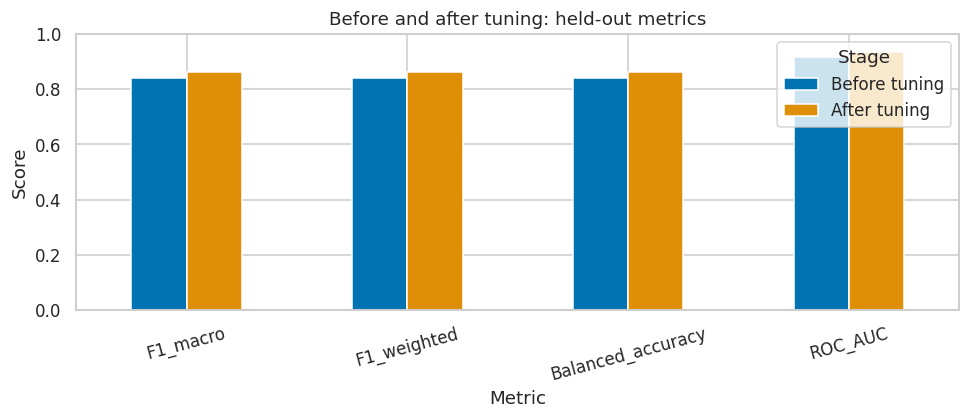

,precision,recall,f1-score,support
Automatic,0.875519,0.844,0.859470,250.000
Manual,0.849421,0.880,0.864440,250.000
accuracy,0.862000,0.862,0.862000,0.862
macro avg,0.862470,0.862,0.861955,500.000
weighted avg,0.862470,0.862,0.861955,500.000


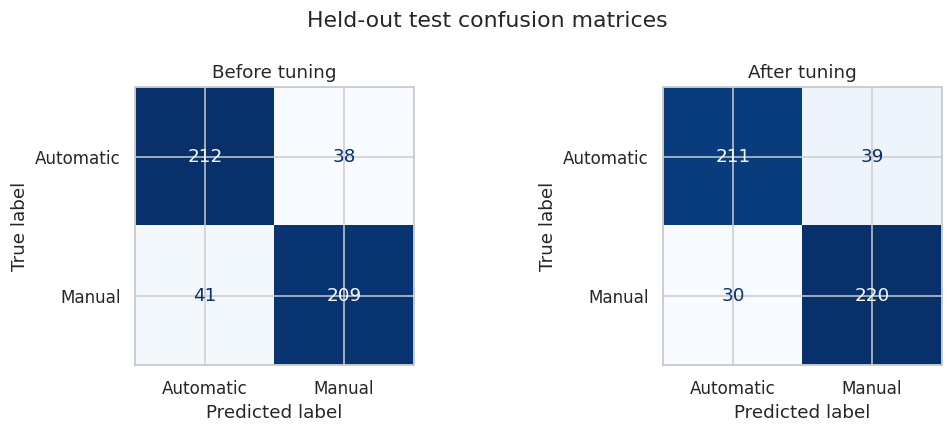

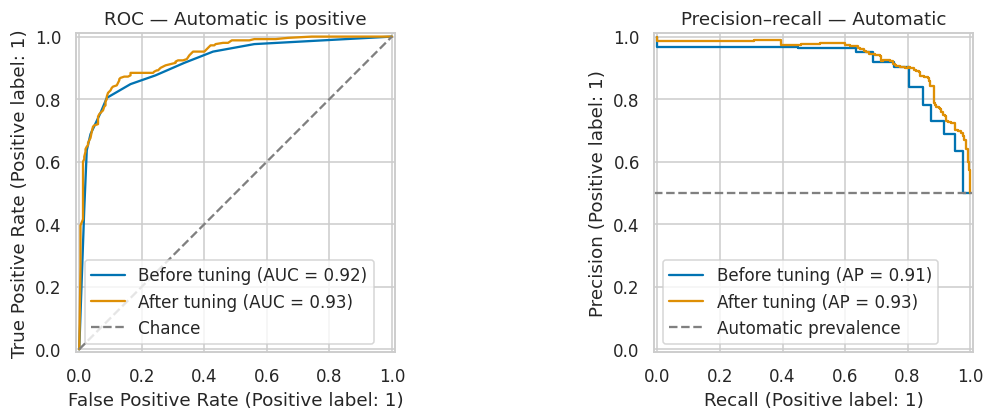

In [6]:
comparison = evaluate_pair(slug, name, baseline, tuned, X_test, y_test,
                           baseline_cv, search, warning_messages)
display(comparison.round(4))
metric_cols = ['Accuracy', 'F1_weighted', 'F1_macro', 'Automatic_recall', 'ROC_AUC', 'CV_macro_F1']
delta = comparison.loc[1, metric_cols] - comparison.loc[0, metric_cols]
display(delta.to_frame('After minus before'))
comparison.set_index('Stage')[['F1_macro', 'F1_weighted', 'Balanced_accuracy', 'ROC_AUC']].T.plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title('Before and after tuning: held-out metrics'); plt.xlabel('Metric'); plt.ylabel('Score')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
display(pd.read_csv(ROOT / 'results' / slug / 'after_class_report.csv', index_col=0))
plot_pair(slug, baseline, tuned, X_test, y_test)


## Team interpretation and viva preparation
Complete these prompts yourself after inspecting the actual outputs:
- Which metric changed most, and by how much? Did test performance improve or decline?
- How many Automatic cars were missed before and after tuning?
- Why is oversampling unnecessary here? What does distinct listing data establish, and what does it not prove?
- Explain this model's training mechanism and the selected hyperparameters.
- Why might CV improvement fail to produce test improvement?

Models and numeric results are exported to `models/` and `results/`. The GUI reads those same files.
Source: [scikit-learn](https://scikit-learn.org/stable/). See data/CLASSIFICATION_DATA_SOURCE.md for dataset provenance.
AI-assisted code scaffolding is disclosed in README. Your interpretation must be original.
